
### Term Project


For this project I will be utilizing the [IBM HR Analytics Employee Attrition & Performance Dataset](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset) from Kaggle.

### Milestone 1

#### Business Problem


This project will focus on a significant issue for all companies - employee turnover. As a previous software engineer, and now a Software Development Manager, this is a very relevant issue that is quite interesting to me. High employee turnover is a significant financial burden on companies; replacing an employee can cost between 1.5 to 2 times that employee's annual salary. This is more than just the cost of hiring a new employee, since attrition also leads to a loss of institutional knowledge and can affect team morale. In some cases, losing high value employees means a loss of specific program knowledge, and in fields like software engineering, losing an integral engineer may mean loss of understanding an entire code base or application. In these cases, the employee is truly invaluable, as there is no way to replace the level of knowledge and intimacy that employee had with the codebase. Companies can no longer simply worry about trying to make changes after a reactive exit interview, but instead should be proactive in retaining good employees. What this project will focus on is trying to identify tipping points, like pay disparity, overtime frequency, and commute distance, in leading to an employee's decision to leave the company. 



#### Target


The target for this model will be a binary classification model for attrition- either yes or no. By predicting the probability of an employee leaving, managers and HR business partners would be able to prioritize interventions like conducting stay interviews, salary adjustments or possibly remote work options for anyone listed as a *high-risk* individual before they submit their resignation.

In [63]:
import pandas as pd

# load the Employee Attrition data into a dataframe
attrition = pd.read_csv('Employee_Attrition.csv')

# display the first few rows of data
attrition.head()


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [64]:
# display dimensions of the dataframe
attrition.shape

(1470, 35)

In [65]:
# check column data types
attrition.dtypes

Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeCount               int64
EmployeeNumber              int64
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
Over18                        str
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StandardHours               int64
StockOptionLevel            int64
TotalWorkingYears           int64
TrainingTimesL

In [66]:
# summary statistics of the numerical data
attrition.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


#### Graphical Analysis


To help understand why people leave a company, visualizing relationships between the features and the attrition target will assist in answering this question.


**Graph 1 Box Plot: Monthly Income vs Attrition**


This will help to determine if there is a disparity in pay between those who stay and those who leave.

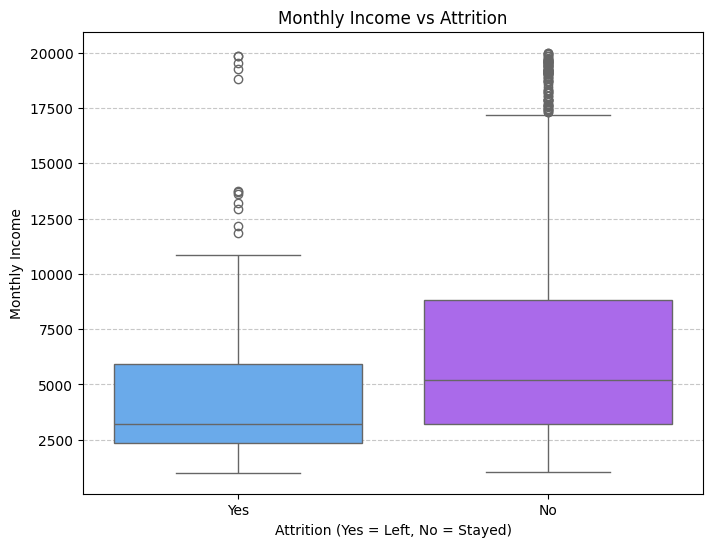

In [67]:
import seaborn as sns
import matplotlib.pyplot as plt

# create box plot: income vs attrition
plt.figure(figsize=(8, 6))
sns.boxplot(data=attrition, x='Attrition', y='MonthlyIncome', hue="Attrition", palette='cool', legend=False)
plt.title('Monthly Income vs Attrition')
plt.xlabel('Attrition (Yes = Left, No = Stayed)')
plt.ylabel('Monthly Income')
plt.grid(axis='y', linestyle='--', alpha=0.7)

**Interpretation**


This visualization clearly shows a divergence in the central tendency of income. The median monthly income for employees who stayed (No) is visibly higher than those who left (Yes). This suggests that compensation is a strong predictive indicator of turnover risk.

There are a number of outliers in the stayed (No) category who represent high-earners who remain at the company, and are most likely senior employees or more executive level (as seen by the large monthly salary). The attrition (Yes) group is more tightly grouped at lower monthly income levels which means the model's sensitivity to income as a predictor will be stronger for junior to mid-level positions. Once the model gets to the higher monthly pay it will most likely have a harder time performing.



**Graph 2 Stacked Bar Chart: Overtime vs Attrition**


This will help to visualize if employees are being burned out with overtime and causing them to quit.

(array([0, 1]), [Text(0, 0, 'No'), Text(1, 0, 'Yes')])

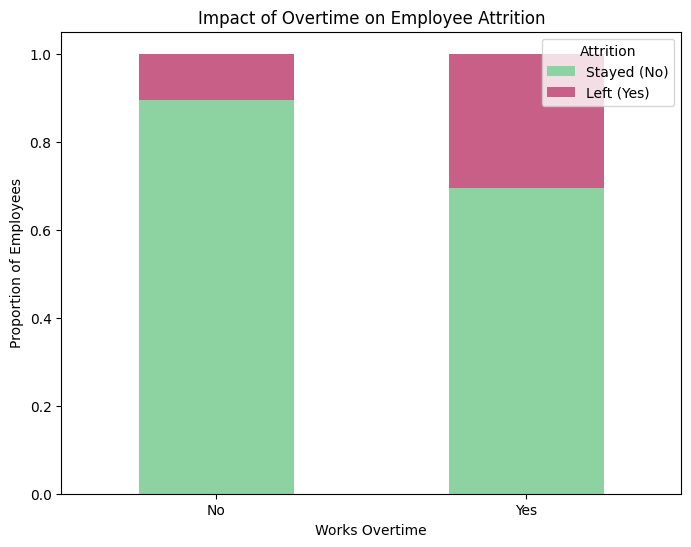

In [68]:
# creating a crosstab for the stacked bar chart
overtime_attrition = pd.crosstab(attrition['OverTime'], attrition['Attrition'], normalize='index')

# plotting
overtime_attrition.plot(kind='bar', stacked=True, color=['#8DD3A2', '#C75F87'], figsize=(8, 6))

plt.title('Impact of Overtime on Employee Attrition')
plt.xlabel('Works Overtime')
plt.ylabel('Proportion of Employees')
plt.legend(title='Attrition', labels=['Stayed (No)', 'Left (Yes)'], loc='upper right')
plt.xticks(rotation=0)

**Interpretation**


This visualization shows a clear relationship between overtime and employee turnover. For those employees not working overtime, attrition is relatively low, however, the proportion of employees who left dramatically increases for those who *do* work overtime. This places overtime as a primary feature with a strong predictive indicator for being able to predict future attrition.

This will be a crucial feature to include for model sensitivity. This will help to identify the employees who are at risk for experiencing burnout and possibly quitting. If I do not take overtime into account there would most likely be a higher Type II, or $\beta$ error as it appears that overtime burnout appears to be a critical driver for the 'Yes' target.



**Graph 3 Correlation Heatmap: Numeric Features**


This will help to identify any multicollinearity (like Age and years at company) and see which variables have the strongest linear relationship with attrition.

There are constant or non-informative fields that do not need to be kept or included in this analysis as it is possible that the constant fields could interfere with the algorithm's convergence or inflate the importance of irrelevant features. Removing these fields will improve the sensitivity of the model and will help to ensure that the model will stay focused on high-variance signals such as *MonthlyIncome* and *Age*.

First, I will encode my target variable of *Attrition* to allow me to better assess numeric relationships with the target.

Text(0.5, 1.0, 'Correlation Heatmap (Encoded Target & Cleaned Features)')

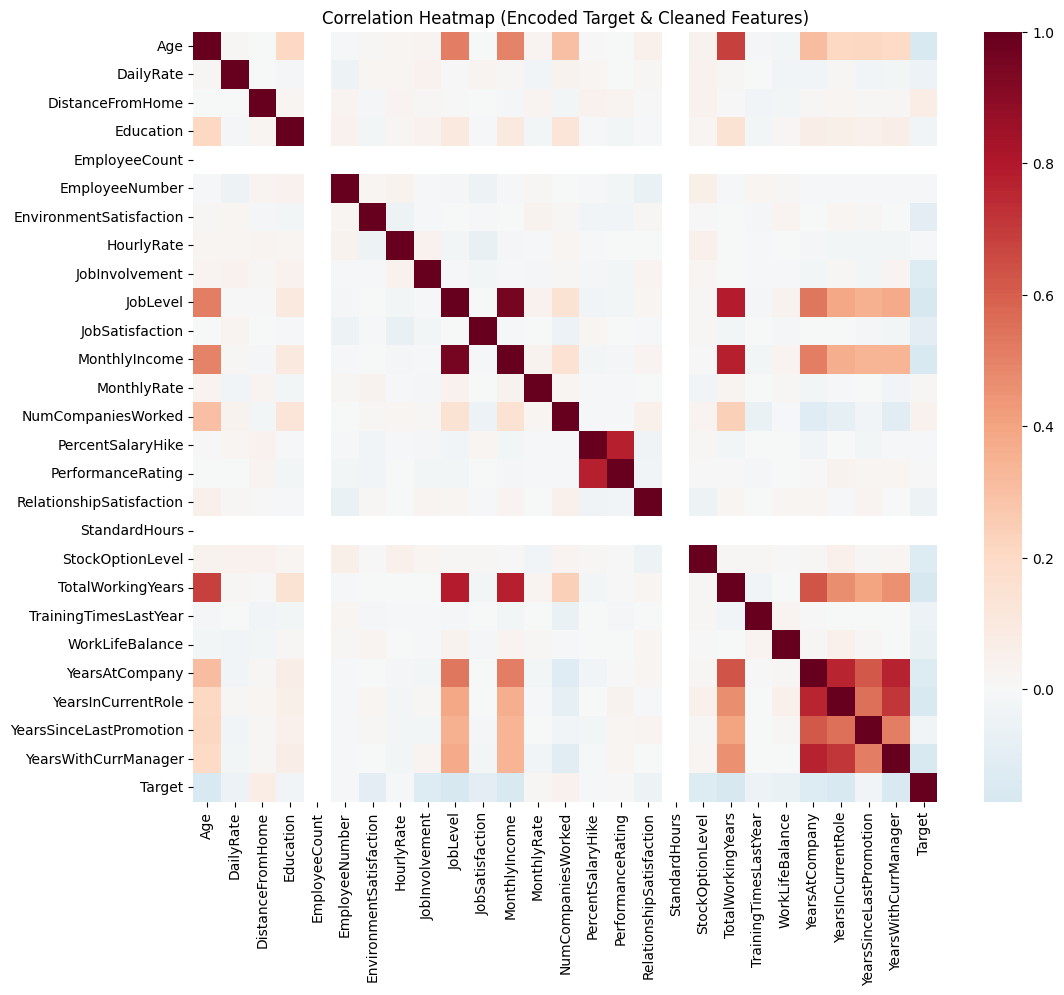

In [69]:
import numpy as np

# encode target variable
attrition['Target'] = attrition['Attrition'].apply(lambda x: 1 if x == 'Yes' else 0)

# select numeric columns and calculate correlation
numeric_attrition = attrition.select_dtypes(include=[np.number])
corr_matrix = numeric_attrition.corr()

# generate the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='RdBu_r', center=0)
plt.title('Correlation Heatmap (Encoded Target & Cleaned Features)')

**Interpretation**


This heatmap identifies strong positive correlations between job level, monthly income, and total working years. This shows, as expected, that both experience and seniority are primary drivers of compensation. With all of these variables providing similar sentiment it may be beneficial to reduce some of these features to prevent overfitting. 

After encoding the target variables, the heatmap is able to show a meaningful pattern regarding turnover. The negative correlation between *TotalWorkingYears* and the *Target* is easily observed now. This suggests that as tenure increases, the likelihood of attrition decreases. The establishes a good baseline for identifying *at-risk* newer employees. A clear negative correlation between *TotalWorkingYears* and *JobLevel* with the likelihood of attrition. This is a measurable signal that seniority and cumulative experience are the strongest stabilizers for the workforce. *MonthlyIncome* shows a prominent inverse relationship with turnover, which confirms that lower compensation is an observable factor in an employee's decision to leave. 


**Graph 4 Violin Plot: Attrition Segmented by Marital Status**


This will help to visualize if employees are more likely to quit if they are younger or single compared to someone married and older, and considered *more settled* in their careers.

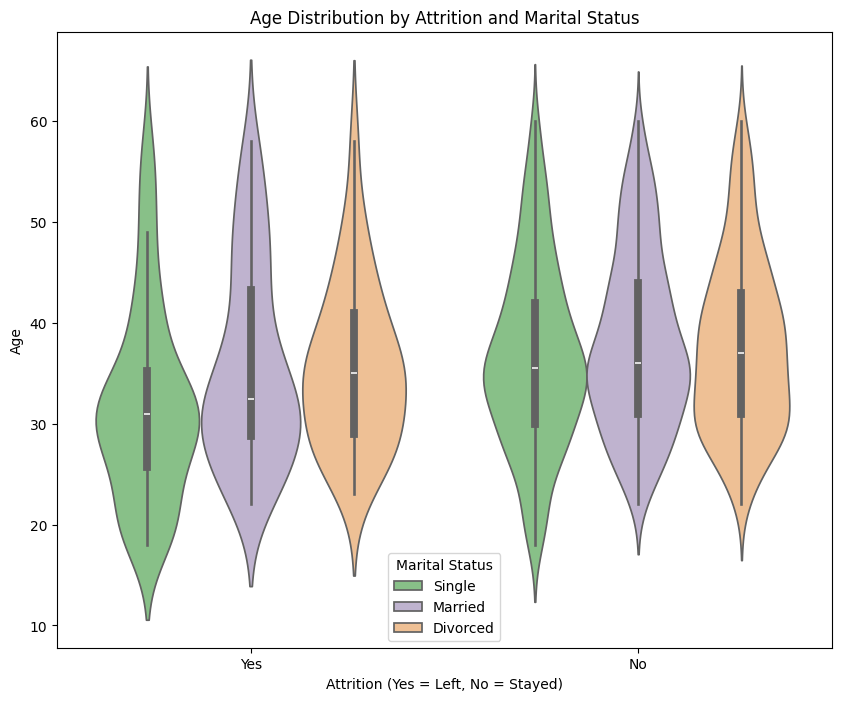

In [70]:
# create the Violin Plot
plt.figure(figsize=(10, 8))
sns.violinplot(data=attrition, x='Attrition', y='Age', hue='MaritalStatus', palette='Accent')

plt.title('Age Distribution by Attrition and Marital Status')
plt.xlabel('Attrition (Yes = Left, No = Stayed)')
plt.ylabel('Age')
plt.legend(title='Marital Status')

**Interpretation**

This plot shows definite signal regarding age. The Yes (on the left) shows that single employees are notably wider at the younger age groups (20-30s) which suggests that life stage and marital status are significant factors in whether the employee stays or quits a company. Single employees have a higher propensity to leave a company compared to married or divorced counterparts where the plots show a more stable, centered distribution. 

The No (on the right) shows a more consistent, bell-shaped distribution across each of the marital status categories, as well as a higher median age. This indicates that the sensitivity of the model will likely be highest when identifying turover risk for early-career employees. Older employees that are either married or divorced will represent the most stable group of the workforce and will be a negative control for the risk of attrition.


#### Graphical Analysis Overview/Conclusion

The graphical analysis of this IBM Attrition dataset  identifies several notable patterns that serve as foundational indicators for predicting employee turnover. These graphs provided insight pointing to employee turnover rates not just being random occurrences but a multi-faceted business problem that is driven by specific demographic, operational, and financial indicators. The primary variable identified during this initial analysis is the intersection of pay and workload. By encoding the target and pruning constant feature, I have established that *Total Working Years*, *Monthly Income*, and *Overtime* are the most meaningful predictors. The Monthly Income box plot confirmed that employees who leave companies tend to do so when they are at lower salary bands which suggests that companies lose talentend employees to competitors offering higher entry-level or mid-level wages. It is also known, in some fields (like software engineering), that the only way to get a promotion is to job hop. The Overtime Stacked bar chart also provided clear evidence of burnout being a huge reason for employee attrition. Employees who work overtime had a significant increase in attrition rates. To ensure covering of the demographic portion, the Violin Plot and Marital Status revealed that younger, single employees are more likely to leave a job. This could indicate that companies are not investing in the early career development of their employees enough. The correlation heatmap indicated redundant variables in job level, total working years, and monthly income which will need to be considered as a single variable of *Seniority* to avoid the statistical noise of multicollinearity.

Based on these insights the proposed model will focus on a multi-pronged approach to indentifying turnover risk. High-risk individuals for attrition have been identified as younger, lower-paid and frequently working overtime. In the modeling phase recall will be important to ensure that the model will be sensitive enough to catch these high risk employees even if employees who are not planning to leave are flagged for HR intervention. This strategy will help the HR department to maximize their return on investment for retention efforts, which will directly address the underlying business problem of high replacement costs and loss of institutional knowledge. 

### Milestone 2 - Data Preparation

This phase is focused on converting raw categorical data into a format that will be suitable for use with machine learning algorithms.

**Feature Pruning**

I will begin by removing fields that will not add any beneficial information to the model. Based on my initial review I believe the columns that I will drop are:

- *EmployeeCount*
- *Over18*
- *StandardHours*
- *EmployeeNumber*
- *Attrition*


The first three have constant values across all the rows, with no variance, which means there is nothing for the model to learn or gain from them. The *EmployeeNumber* is a unique identifier for each employee, but it could lead to overfitting, since the model may begin to recognize specific IDs rather than learning the patterns. 
I will remove *Attrition* since I have now encoded it before creating my correlation heatmap<sup>[[Note]](#fn)</sup> and I do not want to have the duplicated column here as it will create noise in the model.


<a id="fn1">Note:</a> Part of Milestone 1 updates

In [71]:
# drop constant or non-informative fields
# StandardHours, EmployeeCount, and Over18 have zero variance
# EmployeeNumber is just a unique ID
# Attrition- I already encoded this so I will remove the duplicate column
drop_columns = ['StandardHours', 'EmployeeCount', 'Over18', 'EmployeeNumber', 'Attrition']
attrition_cleaned = attrition.drop(columns=cols_to_drop)


print(f"Columns dropped: {drop_columns}")

Columns dropped: ['StandardHours', 'EmployeeCount', 'Over18', 'EmployeeNumber', 'Attrition']


Removing these constant fields provide noise reduction which will increase the baseline significance, $\alpha$, of the remaining features and will allow the model's sensitivity, $\beta$, to focus on actual behavioral triggers like overtime.

**Handling Missing Data**

To ensure data integrity I will need to validate that there are no null, NaN, None or empty string values that would negatively affect the model.

In [90]:
# audit for missing values to ensure data integrity
print(f"Null/NaN/None or empty values: {attrition_final.isnull().sum().max()}")

Null/NaN/None or empty values: 0


This check shows there are no null or empty values across this dataset. This is what I expect since this is a dataset from Kaggle and is a fictional dataset created by IBM data scientists. Since there are no null values across all 1,470 records no row deletion or value imputation is required.

**Feature Engineering**

Feature engineering is done to help increase the sensitivity of a model by capturing complex relationships in a single variable. 

First, I will capture the loyalty of an employee. Company loyalty is still very strong for some people, especially among the older generation and, typically, employees who have spent all 10 years of their working years at one company tend to have a different attrition risk than someone who has only spent 10 years out of 30 years there. The value I'm looking to capture is something like tenure density. 
I will create a loyalty ratio feature.

$$LoyaltyRatio = \frac{YearsAtCompany}{TotalWorkingYears}$$


In [73]:
# engineer a new feature: LoyaltyRatio
# adding a small constant to denominator to avoid division by zero
attrition_cleaned['LoyaltyRatio'] = attrition_cleaned['YearsAtCompany'] / (attrition_cleaned['TotalWorkingYears'] + 1)

attrition_cleaned.head()

,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Target,LoyaltyRatio
0,41,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,...,0,8,0,1,6,4,0,5,1,0.666667
1,49,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,...,1,10,3,3,10,7,1,7,0,0.909091
2,37,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,...,0,7,3,3,0,0,0,0,1,0.000000
3,33,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,56,...,0,8,3,3,8,7,3,0,0,0.888889
4,27,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,40,...,1,6,3,3,2,2,2,2,0,0.285714


**Consolidation**

Through the correlation heatmap, I can see that *JobLevel*, *MonthlyIncome*, and *TotalWorkingYears* variables are highly correlated and will distract the model due to the redundancy of the data. To combat this I will consolidate these variables into what these three variables are really representing, *Seniority*. Keeping all of these variables can lead to overfitting since the model may over-emphasize this dimension of an employee's seniority. 

I will create a single value of seniority (*SeniorityIndex*) to capture these three variables and capture a standard score (Z-Score) for them for each employee.

$$SeniorityIndex = \frac{z(JL) + z(MI) + z(TWY)}{3}$$

This should help to encapsulate the underlying essence of someone's seniority while trying to smooth possible outliers- like a younger person with a higher salary, or an older person who is newer to the workforce and has a more junior level position. 

In [74]:
from sklearn.preprocessing import StandardScaler

# first standardize the three variables so they are on the same scale
scaler = StandardScaler()
cols = ['JobLevel', 'MonthlyIncome', 'TotalWorkingYears']
attrition_cleaned[cols] = scaler.fit_transform(attrition_cleaned[cols])

# then create a consolidated SeniorityIndex
attrition_cleaned['SeniorityIndex'] = attrition_cleaned[cols].mean(axis=1)

# now drop the originals to prevent redundancy
attrition_cleaned = attrition_cleaned.drop(columns=cols)

attrition_cleaned.head()

,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,StockOptionLevel,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Target,LoyaltyRatio,SeniorityIndex
0,41,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,...,0,0,1,6,4,0,5,1,0.666667,-0.195927
1,49,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,...,1,3,3,10,7,1,7,0,0.909091,-0.171339
2,37,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,...,0,3,3,0,0,0,0,1,0.000000,-0.816449
3,33,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,56,...,0,3,3,8,7,3,0,0,0.888889,-0.715588
4,27,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,40,...,1,3,3,2,2,2,2,0,0.285714,-0.761706


**Categorical Encoding - Dummy Variables**

Since machine learning models require numeric data, any text based categories that the model needs to be able to use must be in a format that the model is able to process.

I have already created the *Target* column and encoded it for the *Attrition* variable before creating my Correlation Heatmap.<sup>[[Note]](#fn1)</sup>

I will also need to do binary encoding on the *OverTime* variable. 

<a id="fn1">Note:</a>  Updated Milestone 1

In [75]:
# binary encoding for OverTime
attrition_cleaned['OverTime'] = attrition_cleaned['OverTime'].apply(lambda x: 1 if x == 'Yes' else 0)
print("Encoded OverTime")
attrition_cleaned.head(2)

Encoded OverTime


,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,StockOptionLevel,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Target,LoyaltyRatio,SeniorityIndex
0,41,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,...,0,0,1,6,4,0,5,1,0.666667,-0.195927
1,49,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,...,1,3,3,10,7,1,7,0,0.909091,-0.171339


For multi-categorical features like the *JobRole* and *MaritalStatus* I can use one-hot encoding and dummy variables to ensure the model does not try to assume mathematical ranking between categories.

In [76]:
# create dummy variables for remaining multi-categorical features
# this will turn 'MaritalStatus' into 'MaritalStatus_Married', 'MaritalStatus_Single', etc.
attrition_final = pd.get_dummies(attrition_cleaned, columns=[
    'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus'
], drop_first=True)

attrition_final.head()

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobSatisfaction,MonthlyRate,NumCompaniesWorked,...,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
0,41,1102,1,2,2,94,3,4,19479,8,...,False,False,False,False,False,False,True,False,False,True
1,49,279,8,1,3,61,2,2,24907,1,...,False,False,False,False,False,True,False,False,True,False
2,37,1373,2,2,4,92,2,3,2396,6,...,False,True,False,False,False,False,False,False,False,True
3,33,1392,3,4,4,56,3,3,23159,1,...,False,False,False,False,False,True,False,False,True,False
4,27,591,2,1,1,40,3,2,16632,9,...,False,True,False,False,False,False,False,False,True,False


Machine learning algorithms are mathematical models that perform operations like addition and multiplication on numerical vectors. Since they canot directly calculate a 'distance' or 'slope' for a string, this data must be converted to a numerical format. Therefore, I performed one-hot encoding on the categorical features and created dummy variables to turn these into multiple binary (true/false) values that the model will be able to utilize. I utilized the `drop_first=True` parameter to prevent adding any new multicollinearity into the model, and to avoid what is known as the dummy variable trap.


**Standardization/Scaling**

Since I standardized the Z-scores for the *SeniorityIndex* I am going to scale my remaining numeric features. Depending on the model that I chose, if I do not scale the remaining numeric features they will dominate the model's coefficients, especially features like *Age*, *DistanceFromHome*, and *HourlyRate*. 

In [91]:
# initialize the scaler
scaler = StandardScaler()

# define the remaining numeric columns that still need scaling
# exclude 'Target' and the one-hot encoded dummy variables (0/1)
numeric_features = [
    'Age', 'DailyRate', 'DistanceFromHome', 'Education', 
    'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 
    'JobSatisfaction', 'MonthlyRate', 'NumCompaniesWorked', 
    'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 
    'StockOptionLevel', 'TrainingTimesLastYear', 'WorkLifeBalance', 
    'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 
    'YearsWithCurrManager', 'LoyaltyRatio'
]

# apply scaling
attrition_final[numeric_features] = scaler.fit_transform(attrition_final[numeric_features])

# verify that the mean is now approx 0 and std is approx 1
print(attrition_final[numeric_features].describe().round(2).loc[['mean', 'std']])

      Age  DailyRate  DistanceFromHome  Education  EnvironmentSatisfaction  \
mean -0.0        0.0               0.0        0.0                      0.0   
std   1.0        1.0               1.0        1.0                      1.0   

      HourlyRate  JobInvolvement  JobSatisfaction  MonthlyRate  \
mean         0.0             0.0             -0.0          0.0   
std          1.0             1.0              1.0          1.0   

      NumCompaniesWorked  ...  PerformanceRating  RelationshipSatisfaction  \
mean                 0.0  ...               -0.0                       0.0   
std                  1.0  ...                1.0                       1.0   

      StockOptionLevel  TrainingTimesLastYear  WorkLifeBalance  \
mean               0.0                    0.0             -0.0   
std                1.0                    1.0              1.0   

      YearsAtCompany  YearsInCurrentRole  YearsSinceLastPromotion  \
mean            -0.0                 0.0                      0

I scaled all of the remaining numerical features to ensure that the baseline signal of each variable is treated equally. This means that any unit changes across features will be comparable. This will ensure model stability and improve the sensitivity of a model like logistic regression and will allow me to directly compare feature importance. I transformed them all using `StandardScaler` to align the remaining feature set with my previously created *SeniorityIndex* to ensure that every input is centered around a mean of zero with unit variance. 


Now I will validate that all my datatypes are as I expect them to be and ready for modeling.

In [84]:
# validating datatypes to ensure readiness for modeling
print(attrition_final.dtypes.value_counts())

int64      22
bool       20
float64     2
Name: count, dtype: int64


As I begin thinking about the next milestone and modeling I want to perform a quick validation on my target variable to see if it is balanced.

In [85]:
print("Target Distribution (Proportions):")
print(attrition_final['Target'].value_counts(normalize=True))

Target Distribution (Proportions):
Target
0    0.838776
1    0.161224
Name: proportion, dtype: float64


This check helps to determine if my model will be biased toward the majority group. This count shows me that the distribution of my dataset shows 84% of the employees did not attrit, or leave the company, and 16% did attrit. This is a class imbalance and I will need to be sure to consider the accuracy of the model when I get there as it may be misleading. I will need to ensure that I prioritize Recall and the F1-Score to measure the model's sensitivity to the minority class (the employees who leave).

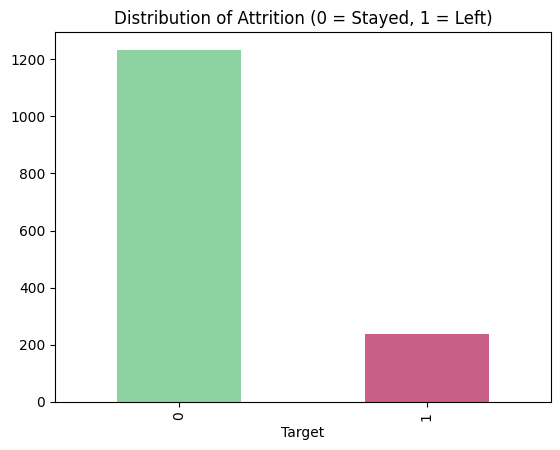

In [87]:
# visual check of the imbalance
attrition_final['Target'].value_counts().plot(kind='bar', color=['#8DD3A2', '#C75F87'])
plt.title('Distribution of Attrition (0 = Stayed, 1 = Left)')
plt.show()

#### Milestone 2 Summary

To avoid data snooping, all feature engineering and selection were performed based on my domain knowledge and EDA trends prior to any model training or data splitting.

I began by removing irrelevant columns that would only add noise to the model, such as constant fields and unique identifiers. I then applied binary encoding to the *OverTime* feature and encoded the target variable of *Attrition* before re-running the correlation heatmap to assess numeric relationships. I then performed one-hot encoding on all multi-categorical variables, using the 'drop first' method to prevent the dummy variable trap and ensure the data is mathematically ready for modeling. 

I conducted a missing value audit which confirmed zero null values across the dataset.

To mitigate multicollinearity and prevent overfitting, I engineered a *SeniorityIndex* by calculating the arithmetic mean of the standardized Z-scores for *JobLevel*, *MonthlyIncome*, and *TotalWorkingYears*. These variables showed high inter-correlation during the graphical analysis/EDA phase. By averaging their standardized Z-scores I am able to capture a single unified metric of career progression while reducing redundant noise in the feature set.

Additionally, a *LoyaltyRatio* variable was created to capture tenure density relative to total career experience.

Finally, I performed an initial check of the target distribution proportions. I observed a class imbalance which will inform my model validation strategy as I move forward with this project.

In [83]:
# exporting current version of my dataframe to a spreadsheet
attrition_final.to_csv('attrition_final.csv', index=False)